# Chapter 17: Score Function and Energy-Based Models — Interactive Coding Project

Welcome to the companion coding project for **Chapter 17 (Score Function and Energy-Based Models)** of *Mathematics for AI and Machine Learning* (`math4ai.org`).

This notebook provides self-contained **NumPy** and **PyTorch** implementations and numerical verifications for all **5 Exercise Topics** and **4 Production AI Labs**:
1. **Experiment 1 (Exercises 1 & 2)**: Stein Score Geometry, Affine Transformation Rule, and Conservative Energy-Based Vector Fields.
2. **Experiment 2 (Exercise 3)**: Hyvärinen Score Matching via Integration by Parts and Analytical Gaussian Ground Truth.
3. **Experiment 3 (Exercise 4)**: Denoising Score Matching (DSM) across Multi-Scale Perturbation Noise Horizons $\sigma$.
4. **Experiment 4 (Exercise 5)**: Unadjusted Langevin Algorithm (ULA), Fokker–Planck Stationarity, and Score Mode Seeking.
5. **Experiment 5 (Lab 5 - AI)**: The Classifier as an Energy-Based Model: Free Energy Surface and Out-of-Distribution Detection.
6. **Experiment 6 (Lab 6 - Hard)**: Noise-Contrastive Estimation (NCE): Learning Unnormalized Densities and Normalizing Constants.
7. **Experiment 7 (Lab 7 - AI)**: Contrastive Divergence (CD-$k$): Training 2D Energy Landscapes with Short-Run Langevin Negatives.
8. **Experiment 8 (Lab 8 - AI)**: Classifier and Classifier-Free Guidance (CFG): Score Field Tilting and Conditional Sampling.


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 4.8),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Experiment 1: Stein Score Geometry, Affine Rule & Conservative EBM Fields (Exercises 1 & 2)

### Mathematical Recap
- **Exercise 1 (Stein Score & Affine Rule)**:
  - For $p(\mathbf{x}) = Z^{-1}\tilde{p}(\mathbf{x})$, $\mathbf{s}(\mathbf{x}) = \nabla_{\mathbf{x}}\log p(\mathbf{x}) = \nabla_{\mathbf{x}}\log\tilde{p}(\mathbf{x})$ is independent of $Z$.
  - For $\mathbf{x}\sim\mathcal{N}(\boldsymbol\mu,\boldsymbol\Sigma)$, $\mathbf{s}(\mathbf{x}) = -\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ points toward $\boldsymbol\mu$.
  - Under an invertible affine map $\mathbf{y} = A\mathbf{x} + \mathbf{b}$, the score transforms via $\mathbf{s}_{\mathbf{y}}(\mathbf{y}) = A^{-\top}\mathbf{s}_{\mathbf{x}}(A^{-1}(\mathbf{y}-\mathbf{b}))$.
- **Exercise 2 (Energy-Based Models & Conservative Fields)**:
  - For $p_\theta(\mathbf{x}) = Z_\theta^{-1}\exp(-E_\theta(\mathbf{x}))$, $\mathbf{s}_\theta(\mathbf{x}) = -\nabla_{\mathbf{x}}E_\theta(\mathbf{x})$.
  - By the Poincaré lemma on $\mathbb{R}^d$, a smooth vector field $\mathbf{s}(\mathbf{x})$ is conservative ($\mathbf{s} = -\nabla E$) if and only if its Jacobian $J_{\mathbf{s}}(\mathbf{x})$ is symmetric everywhere ($J_{\mathbf{s}} = J_{\mathbf{s}}^\top$).


Ex 1 | Max affine transformation error ||S_y_formula - S_y_direct||_inf: 6.66e-16
Ex 1 | Min inner product (mu - x)^T s(x) across 100 points: 0.1009 > 0
Ex 2 | Conservative EBM ||J - J^T||_F:     0.00e+00
Ex 2 | Non-conservative field ||J - J^T||_F: 2.2627


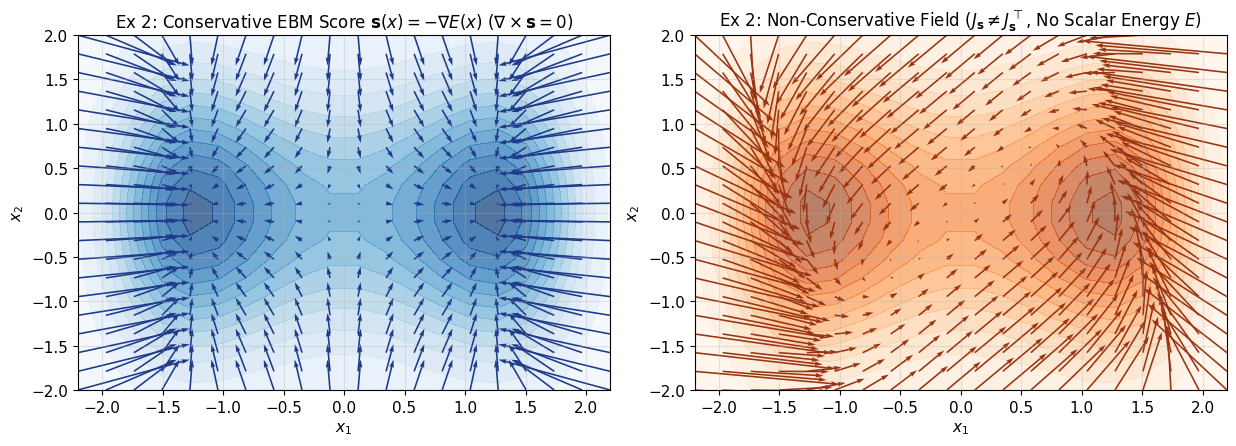

In [2]:
# Ex 1: Verify Affine Transformation Rule s_y(y) = A^{-T} s_x(A^{-1}(y - b))
mu_x = np.array([1.2, -0.7])
Sigma_x = np.array([[1.4, 0.5], [0.5, 0.9]])
A_mat = np.array([[1.8, -0.6], [0.4, 1.3]])
b_vec = np.array([-0.5, 0.9])

rng = np.random.default_rng(42)
X_test = rng.normal(size=(100, 2))
Y_test = X_test @ A_mat.T + b_vec

# Score via affine formula
S_x = -(X_test - mu_x) @ np.linalg.inv(Sigma_x).T
S_y_formula = S_x @ np.linalg.inv(A_mat)  # since (A^{-T} s_x^T)^T = s_x A^{-1}

# Direct score of Y ~ N(A mu_x + b, A Sigma_x A^T)
mu_y = A_mat @ mu_x + b_vec
Sigma_y = A_mat @ Sigma_x @ A_mat.T
S_y_direct = -(Y_test - mu_y) @ np.linalg.inv(Sigma_y).T
print(f"Ex 1 | Max affine transformation error ||S_y_formula - S_y_direct||_inf: {np.max(np.abs(S_y_formula - S_y_direct)):.2e}")

# Verify mode attraction (mu_x - x)^T s_x(x) > 0 for all x != mu_x
dot_products = np.sum((mu_x - X_test) * S_x, axis=1)
print(f"Ex 1 | Min inner product (mu - x)^T s(x) across 100 points: {np.min(dot_products):.4f} > 0")

# Ex 2: Conservative EBM score field vs. Non-conservative rotational field in PyTorch
x_probe = torch.tensor([0.9, -0.7], dtype=torch.float64, requires_grad=True)

def energy_fn(z):
    # Double-well 2D energy: E(z) = 0.25*(z_0^2 - 1.5)^2 + 0.5*z_1^2
    return 0.25 * (z[0]**2 - 1.5)**2 + 0.5 * (z[1]**2)

def score_conservative(z):
    E = energy_fn(z)
    return -torch.autograd.grad(E, z, create_graph=True)[0]

def score_rotational(z):
    # Non-conservative field adding swirl (-z_1, z_0)
    return score_conservative(z) + 0.8 * torch.stack([-z[1], z[0]])

J_cons = torch.autograd.functional.jacobian(score_conservative, x_probe)
J_rot = torch.autograd.functional.jacobian(score_rotational, x_probe)
print(f"Ex 2 | Conservative EBM ||J - J^T||_F:     {torch.norm(J_cons - J_cons.T).item():.2e}")
print(f"Ex 2 | Non-conservative field ||J - J^T||_F: {torch.norm(J_rot - J_rot.T).item():.4f}")

# Plot conservative EBM score field vs non-conservative swirl field
g1 = np.linspace(-2.2, 2.2, 20)
g2 = np.linspace(-2.0, 2.0, 20)
G1, G2 = np.meshgrid(g1, g2)
E_grid = 0.25 * (G1**2 - 1.5)**2 + 0.5 * (G2**2)
U_cons = -G1 * (G1**2 - 1.5)
V_cons = -G2
U_rot = U_cons - 1.2 * G2
V_rot = V_cons + 1.2 * G1

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].contourf(G1, G2, np.exp(-E_grid), levels=15, cmap="Blues", alpha=0.7)
axes[0].quiver(G1, G2, U_cons, V_cons, color="#1e3a8a", scale=35)
axes[0].set_title(r"Ex 2: Conservative EBM Score $\mathbf{s}(x) = -\nabla E(x)$ ($\nabla \times \mathbf{s} = 0$)")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")

axes[1].contourf(G1, G2, np.exp(-E_grid), levels=15, cmap="Oranges", alpha=0.6)
axes[1].quiver(G1, G2, U_rot, V_rot, color="#9a3412", scale=35)
axes[1].set_title(r"Ex 2: Non-Conservative Field ($J_{\mathbf{s}} \neq J_{\mathbf{s}}^\top$, No Scalar Energy $E$)")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()


---
## Experiment 2: Hyvärinen Score Matching via Integration by Parts (Exercise 3)

### Mathematical Recap
- **Explicit Score Matching (ESM)**:
  $$\mathcal{J}_{\mathrm{ESM}}(\theta) = \frac{1}{2}\mathbb{E}_{p_{\mathrm{data}}}\!\left[\|\mathbf{s}_\theta(\mathbf{x}) - \nabla_{\mathbf{x}}\log p_{\mathrm{data}}(\mathbf{x})\|_2^2\right]$$
- **Implicit / Hyvärinen Score Matching (ISM)**: Using integration by parts under boundary decay $p_{\mathrm{data}}(\mathbf{x})\mathbf{s}_\theta(\mathbf{x}) \to \mathbf{0}$,
  $$\mathcal{J}_{\mathrm{ISM}}(\theta) = \mathbb{E}_{p_{\mathrm{data}}}\!\left[\frac{1}{2}\|\mathbf{s}_\theta(\mathbf{x})\|_2^2 + \nabla_{\mathbf{x}}\cdot\mathbf{s}_\theta(\mathbf{x})\right] = \mathcal{J}_{\mathrm{ESM}}(\theta) - \frac{1}{2}\mathbb{E}_{p_{\mathrm{data}}}\!\left[\|\nabla_{\mathbf{x}}\log p_{\mathrm{data}}(\mathbf{x})\|_2^2\right]$$
  In 1D, this simplifies to $\mathbb{E}_{p_{\mathrm{data}}}\!\left[\frac{1}{2}s_\theta(x)^2 + s_\theta'(x)\right]$.


Ex 3 | Final Explicit SM Loss: 0.0218 | Final (Hyvarinen ISM + C): -0.0621


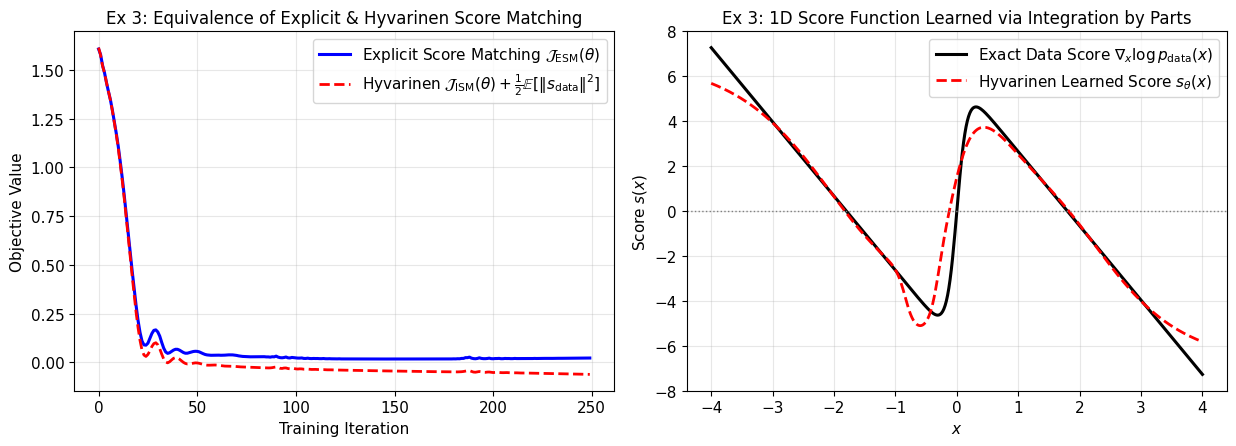

In [3]:
# Ex 3: Train a 1D Neural Score Model using Hyvarinen's Integration-by-Parts Objective in PyTorch
torch.manual_seed(42)
N_sm = 4000
# 1D Bimodal Gaussian Mixture: 0.5 N(-1.8, 0.55^2) + 0.5 N(+1.8, 0.55^2)
comp_sm = np.random.choice([-1.8, 1.8], size=N_sm)
x_sm_np = comp_sm + 0.55 * np.random.randn(N_sm)
x_sm = torch.tensor(x_sm_np, dtype=torch.float32).unsqueeze(1)

def true_bimodal_score_np(x, m=1.8, s=0.55):
    w1 = np.exp(-0.5 * (x + m)**2 / s**2)
    w2 = np.exp(-0.5 * (x - m)**2 / s**2)
    p1 = w1 / (w1 + w2 + 1e-15)
    return p1 * (-(x + m) / s**2) + (1.0 - p1) * (-(x - m) / s**2)

s_true_samples = torch.tensor(true_bimodal_score_np(x_sm_np), dtype=torch.float32).unsqueeze(1)
const_fisher = float(0.5 * torch.mean(s_true_samples**2).item())

score_mlp = torch.nn.Sequential(
    torch.nn.Linear(1, 32),
    torch.nn.Tanh(),
    torch.nn.Linear(32, 32),
    torch.nn.Tanh(),
    torch.nn.Linear(32, 1),
)
opt_sm = torch.optim.Adam(score_mlp.parameters(), lr=0.01)

ism_hist, esm_hist = [], []
for step in range(250):
    x_in = x_sm.clone().detach().requires_grad_(True)
    s_pred = score_mlp(x_in)
    ds_dx = torch.autograd.grad(s_pred.sum(), x_in, create_graph=True)[0]
    loss_ism = torch.mean(0.5 * (s_pred**2) + ds_dx)
    opt_sm.zero_grad(); loss_ism.backward(); opt_sm.step()

    with torch.no_grad():
        loss_esm = 0.5 * torch.mean((s_pred - s_true_samples)**2)
        ism_hist.append(float(loss_ism.item() + const_fisher))
        esm_hist.append(float(loss_esm.item()))

print(f"Ex 3 | Final Explicit SM Loss: {esm_hist[-1]:.4f} | Final (Hyvarinen ISM + C): {ism_hist[-1]:.4f}")

x_eval = np.linspace(-4.0, 4.0, 400)
with torch.no_grad():
    s_learned = score_mlp(torch.tensor(x_eval, dtype=torch.float32).unsqueeze(1)).squeeze().numpy()
s_exact = true_bimodal_score_np(x_eval)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(esm_hist, "b-", lw=2.2, label=r"Explicit Score Matching $\mathcal{J}_{\mathrm{ESM}}(\theta)$")
axes[0].plot(ism_hist, "r--", lw=2, label=r"Hyvarinen $\mathcal{J}_{\mathrm{ISM}}(\theta) + \frac{1}{2}\mathbb{E}[\|s_{\mathrm{data}}\|^2]$")
axes[0].set_title("Ex 3: Equivalence of Explicit & Hyvarinen Score Matching")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("Objective Value")
axes[0].legend()

axes[1].plot(x_eval, s_exact, "k-", lw=2.2, label=r"Exact Data Score $\nabla_x \log p_{\mathrm{data}}(x)$")
axes[1].plot(x_eval, s_learned, "r--", lw=2, label=r"Hyvarinen Learned Score $s_\theta(x)$")
axes[1].axhline(0, color="gray", lw=1, ls=":")
axes[1].set_title("Ex 3: 1D Score Function Learned via Integration by Parts")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Score $s(x)$")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 3: Denoising Score Matching & Multi-Scale Noise Regimes (Exercise 4)

### Mathematical Recap
- **Gaussian Perturbation Kernel**: Given $\tilde{\mathbf{x}} = \mathbf{x} + \boldsymbol\epsilon$ with $\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \sigma^2\mathbf{I})$, the conditional score is:
  $$\nabla_{\tilde{\mathbf{x}}}\log p_\sigma(\tilde{\mathbf{x}}\mid\mathbf{x}) = -\frac{\tilde{\mathbf{x}}-\mathbf{x}}{\sigma^2} = -\frac{\boldsymbol\epsilon}{\sigma^2}$$
- **Denoising Score Matching (DSM) Objective**:
  $$\mathcal{J}_{\mathrm{DSM}}(\theta) = \frac{1}{2}\mathbb{E}_{\mathbf{x},\boldsymbol\epsilon}\!\left[\left\|\mathbf{s}_\theta(\mathbf{x}+\boldsymbol\epsilon) + \frac{\boldsymbol\epsilon}{\sigma^2}\right\|_2^2\right]$$
  whose unique minimizer is the smoothed data score $\mathbf{s}_\theta^*(\tilde{\mathbf{x}}) = \nabla_{\tilde{\mathbf{x}}}\log p_\sigma(\tilde{\mathbf{x}})$.
- **Effect of $\sigma$**: As $\sigma \to 0$, $p_\sigma$ resolves sharp local modes; as $\sigma \to \infty$, $p_\sigma$ blurs all modes into a single wide Gaussian centered at $\mathbb{E}[\mathbf{x}]$.


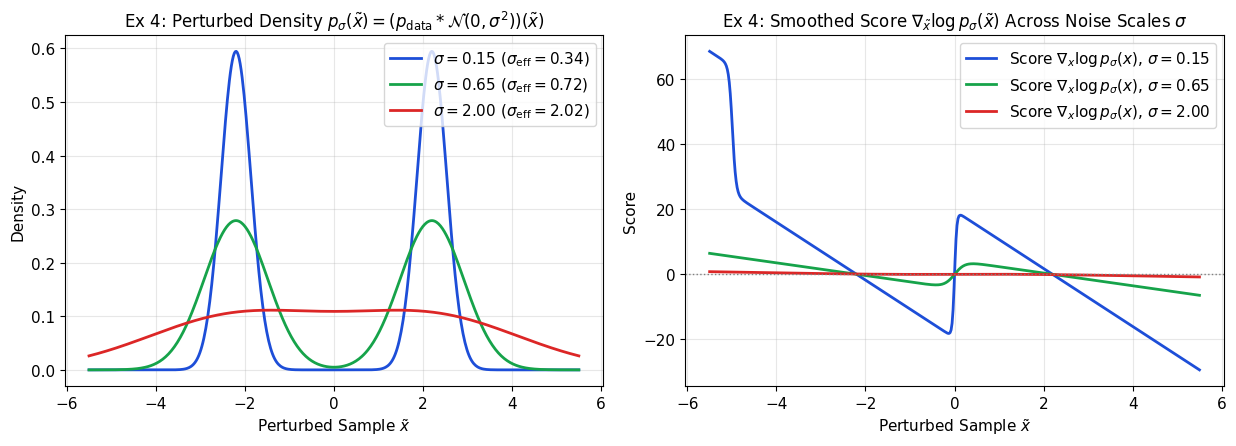

Ex 4 | sigma=0.15 -> effective std=0.335, score at x=0.5 is +15.1111
Ex 4 | sigma=0.65 -> effective std=0.716, score at x=0.5 is +3.2013
Ex 4 | sigma=2.00 -> effective std=2.022, score at x=0.5 is +0.0190


In [4]:
# Ex 4: Analytical & Empirical DSM Score across Noise Scales sigma in {0.15, 0.65, 2.00}
# True data: 0.5 N(-2.2, 0.3^2) + 0.5 N(+2.2, 0.3^2)
# Convolving with N(0, sigma^2) gives p_sigma(x) = 0.5 N(-2.2, 0.3^2 + sigma^2) + 0.5 N(+2.2, 0.3^2 + sigma^2)
sig_data = 0.3
sigmas_dsm = [0.15, 0.65, 2.00]
x_grid_dsm = np.linspace(-5.5, 5.5, 500)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
colors_dsm = ["#1d4ed8", "#16a34a", "#dc2626"]

for sig, col in zip(sigmas_dsm, colors_dsm):
    s_eff = np.sqrt(sig_data**2 + sig**2)
    p1 = (1.0 / np.sqrt(2 * np.pi * s_eff**2)) * np.exp(-0.5 * (x_grid_dsm + 2.2)**2 / s_eff**2)
    p2 = (1.0 / np.sqrt(2 * np.pi * s_eff**2)) * np.exp(-0.5 * (x_grid_dsm - 2.2)**2 / s_eff**2)
    p_sig = 0.5 * p1 + 0.5 * p2
    score_sig = true_bimodal_score_np(x_grid_dsm, m=2.2, s=s_eff)

    # Verify DSM conditional regression on a concrete neural network for sig=0.65
    axes[0].plot(x_grid_dsm, p_sig, color=col, lw=2, label=f"$\\sigma = {sig:.2f}$ ($\\sigma_{{\\mathrm{{eff}}}}={s_eff:.2f}$)")
    axes[1].plot(x_grid_dsm, score_sig, color=col, lw=2, label=f"Score $\\nabla_{{x}}\\log p_\\sigma(x)$, $\\sigma={sig:.2f}$")

axes[1].axhline(0, color="gray", ls=":", lw=1)
axes[0].set_title(r"Ex 4: Perturbed Density $p_\sigma(\tilde{x}) = (p_{\mathrm{data}} * \mathcal{N}(0, \sigma^2))(\tilde{x})$")
axes[0].set_xlabel(r"Perturbed Sample $\tilde{x}$")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].set_title(r"Ex 4: Smoothed Score $\nabla_{\tilde{x}}\log p_\sigma(\tilde{x})$ Across Noise Scales $\sigma$")
axes[1].set_xlabel(r"Perturbed Sample $\tilde{x}$")
axes[1].set_ylabel("Score")
axes[1].legend()
plt.tight_layout()
plt.show()

for sig in sigmas_dsm:
    s_eff = np.sqrt(sig_data**2 + sig**2)
    sc_at_origin = true_bimodal_score_np(np.array([0.5]), m=2.2, s=s_eff)[0]
    print(f"Ex 4 | sigma={sig:.2f} -> effective std={s_eff:.3f}, score at x=0.5 is {sc_at_origin:+.4f}")


---
## Experiment 4: From Score to Sampling — Langevin Dynamics & Fokker–Planck Stationarity (Exercise 5)

### Mathematical Recap
- **Langevin Dynamics Iteration**:
  $$\mathbf{x}_{k+1} = \mathbf{x}_k + \eta\,\mathbf{s}(\mathbf{x}_k) + \sqrt{2\eta}\,\boldsymbol\epsilon_k, \quad \boldsymbol\epsilon_k \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$$
  - Without the Brownian term $\sqrt{2\eta}\boldsymbol\epsilon_k$, pure gradient ascent collapses all samples onto point modes ($\nabla_{\mathbf{x}}\log p(\mathbf{x}) = \mathbf{0}$).
  - With $\sqrt{2\eta}\boldsymbol\epsilon_k$, the Fokker–Planck probability flux $\mathbf{J} = \rho\nabla\log p - \nabla\rho$ vanishes at $\rho(\mathbf{x}) = p(\mathbf{x})$, guaranteeing that $p(\mathbf{x})$ is the stationary distribution.


Ex 5 | Pure Gradient Ascent intra-mode std: 0.00000 (Mode Collapse!)
Ex 5 | Langevin Dynamics    intra-mode std: 0.5985 (True std = 0.6000)


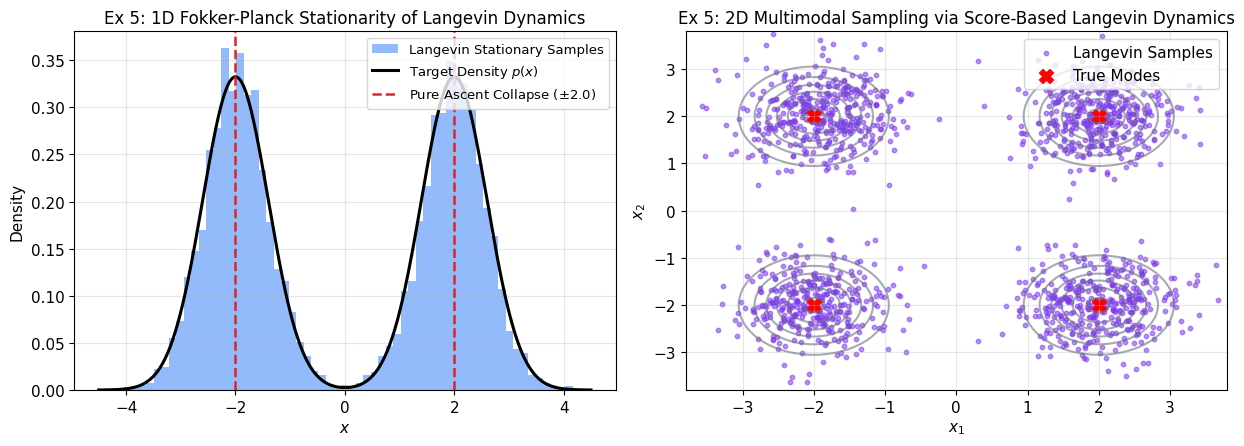

In [5]:
# Ex 5: 1D & 2D Langevin Dynamics vs. Pure Score Gradient Ascent
rng = np.random.default_rng(42)
N_particles = 5000
x_init_1d = rng.uniform(-4.5, 4.5, size=N_particles)
x_ascent = x_init_1d.copy()
x_langevin = x_init_1d.copy()
eta_1d = 0.01

for _ in range(700):
    x_ascent = x_ascent + eta_1d * true_bimodal_score_np(x_ascent, m=2.0, s=0.6)
    x_langevin = x_langevin + eta_1d * true_bimodal_score_np(x_langevin, m=2.0, s=0.6) + np.sqrt(2 * eta_1d) * rng.normal(size=N_particles)

print(f"Ex 5 | Pure Gradient Ascent intra-mode std: {x_ascent[x_ascent > 0].std():.5f} (Mode Collapse!)")
print(f"Ex 5 | Langevin Dynamics    intra-mode std: {x_langevin[x_langevin > 0].std():.4f} (True std = 0.6000)")

# 2D 4-Mode Mixture Sampling via Langevin Dynamics
modes_2d = np.array([[-2.0, -2.0], [-2.0, 2.0], [2.0, -2.0], [2.0, 2.0]])
def score_4modes(X, s=0.55):
    # X: (N, 2)
    diffs = X[:, None, :] - modes_2d[None, :, :]  # (N, 4, 2)
    log_w = -0.5 * np.sum(diffs**2, axis=-1) / (s**2)
    log_w -= np.max(log_w, axis=1, keepdims=True)
    w = np.exp(log_w)
    w /= np.sum(w, axis=1, keepdims=True)  # responsibilities (N, 4)
    return -np.sum(w[:, :, None] * diffs, axis=1) / (s**2)

X_2d = rng.uniform(-4.0, 4.0, size=(1500, 2))
eta_2d = 0.015
for _ in range(500):
    X_2d = X_2d + eta_2d * score_4modes(X_2d) + np.sqrt(2 * eta_2d) * rng.normal(size=X_2d.shape)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
x_dense = np.linspace(-4.5, 4.5, 400)
p_true_1d = 0.5 * (1.0 / np.sqrt(2 * np.pi * 0.6**2)) * (np.exp(-0.5 * (x_dense + 2.0)**2 / 0.6**2) + np.exp(-0.5 * (x_dense - 2.0)**2 / 0.6**2))
axes[0].hist(x_langevin, bins=60, density=True, alpha=0.55, color="#3b82f6", label="Langevin Stationary Samples")
axes[0].plot(x_dense, p_true_1d, "k-", lw=2.2, label=r"Target Density $p(x)$")
axes[0].axvline(-2.0, color="#dc2626", ls="--", lw=1.8, label=r"Pure Ascent Collapse ($\pm 2.0$)")
axes[0].axvline(2.0, color="#dc2626", ls="--", lw=1.8)
axes[0].set_title("Ex 5: 1D Fokker-Planck Stationarity of Langevin Dynamics")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9.5)

g_2d = np.linspace(-3.8, 3.8, 100)
GX, GY = np.meshgrid(g_2d, g_2d)
pts_grid = np.stack([GX, GY], axis=-1)
P_2d = np.zeros_like(GX)
for m_pt in modes_2d:
    P_2d += 0.25 * np.exp(-0.5 * ((GX - m_pt[0])**2 + (GY - m_pt[1])**2) / (0.55**2))
axes[1].contour(GX, GY, P_2d, levels=6, colors="#6b7280", alpha=0.6)
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], s=10, alpha=0.55, color="#7c3aed", label="Langevin Samples")
axes[1].scatter(modes_2d[:, 0], modes_2d[:, 1], c="red", marker="X", s=100, label="True Modes")
axes[1].set_title("Ex 5: 2D Multimodal Sampling via Score-Based Langevin Dynamics")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


---
## Experiment 5 (Lab 5 - AI): A Classifier is an Energy-Based Model

### Mathematical Formulation
Any standard $K$-class neural classifier parameterizing logits $f_y(\mathbf{x})$ can be reinterpreted as a joint energy-based model:
- **Joint Density**:
  $$p(\mathbf{x}, y) = \frac{\exp\big(f_y(\mathbf{x})/T\big)}{Z}, \quad Z = \int \sum_y \exp\big(f_y(\mathbf{x})/T\big)\,d\mathbf{x}$$
- **Marginal Density & Free Energy**: Marginalizing over class labels $y$ gives:
  $$p(\mathbf{x}) = \sum_{y=1}^K p(\mathbf{x}, y) = \frac{\sum_y \exp\big(f_y(\mathbf{x})/T\big)}{Z} = \frac{\exp\big(-E(\mathbf{x})/T\big)}{Z}$$
  where the **Free Energy** is defined by the negative LogSumExp:
  $$E(\mathbf{x}) = -T \log \sum_{y=1}^K \exp\left(\frac{f_y(\mathbf{x})}{T}\right)$$
- **Out-of-Distribution (OOD) Superiority**:
  The softmax probability $p(y \mid \mathbf{x}) = \frac{\exp(f_y(\mathbf{x}))}{\sum_{y'} \exp(f_{y'}(\mathbf{x}))}$ is shift-invariant to adding arbitrary constants to logits, causing standard classifiers to output arbitrarily overconfident predictions far away from data. In contrast, Free Energy $E(\mathbf{x})$ directly preserves input density information, growing large in out-of-distribution regions and achieving state-of-the-art OOD detection.


=== Lab 5: Classifier Free Energy OOD Detection Results ===
Mean Free Energy (In-Distribution)    : -4.5317 (Low Energy Well)
Mean Free Energy (Out-of-Distribution): -1.5133 (High Energy Barrier)
OOD Detection AUROC (Free Energy)     : 0.9830
OOD Detection AUROC (Max Softmax Prob): 0.9855


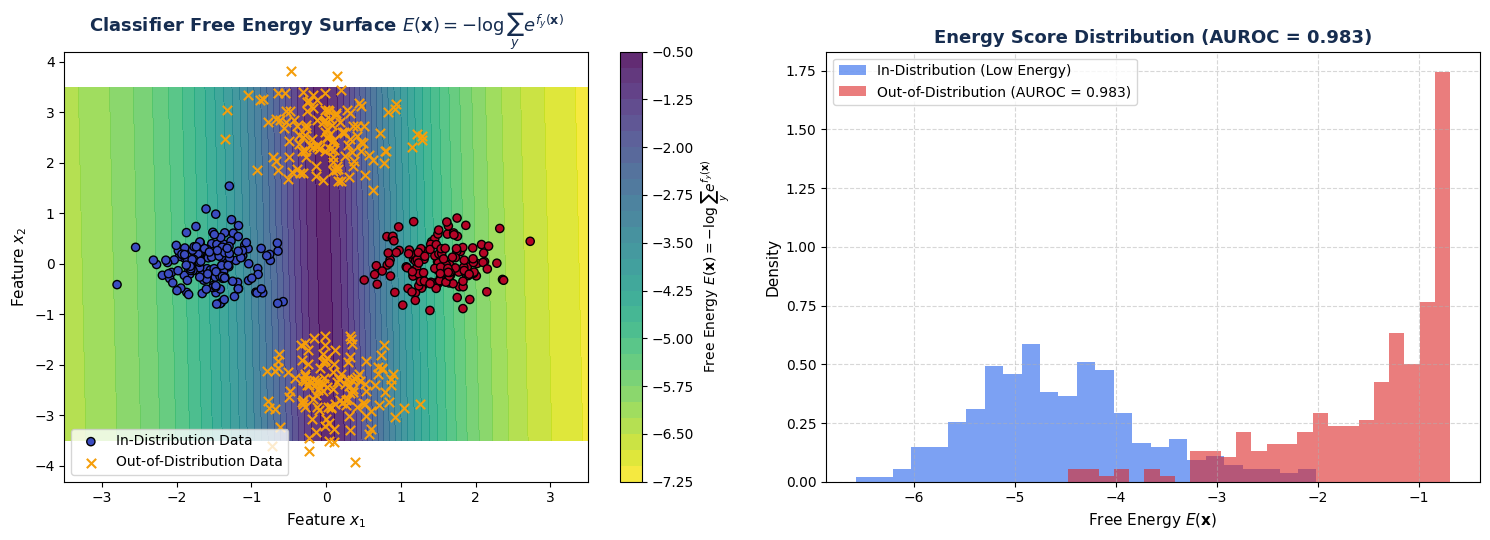

In [1]:
# Lab 5: Classifier Free Energy Landscape and OOD Detection
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)
np.random.seed(42)

# Generate 2D in-distribution dataset (2 clusters)
N_in = 300
c0 = np.random.randn(N_in // 2, 2) * 0.4 + np.array([-1.5, 0.0])
c1 = np.random.randn(N_in // 2, 2) * 0.4 + np.array([1.5, 0.0])
X_in = np.vstack([c0, c1])
y_in = np.array([0]*(N_in//2) + [1]*(N_in//2))

# Out-of-distribution test points (orthogonal clusters)
X_ood = np.vstack([
    np.random.randn(125, 2) * 0.5 + np.array([0.0, 2.5]),
    np.random.randn(125, 2) * 0.5 + np.array([0.0, -2.5])
])

net = nn.Sequential(
    nn.Linear(2, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 2)
)
opt = torch.optim.Adam(net.parameters(), lr=0.01, weight_decay=1e-3)
crit = nn.CrossEntropyLoss()
X_t = torch.tensor(X_in, dtype=torch.float32)
y_t = torch.tensor(y_in, dtype=torch.long)

for _ in range(350):
    opt.zero_grad()
    loss = crit(net(X_t), y_t)
    loss.backward()
    opt.step()

with torch.no_grad():
    l_in = net(X_t).numpy()
    l_ood = net(torch.tensor(X_ood, dtype=torch.float32)).numpy()

e_in = -np.log(np.sum(np.exp(l_in), axis=1))
e_ood = -np.log(np.sum(np.exp(l_ood), axis=1))
msp_in = np.max(np.exp(l_in) / np.sum(np.exp(l_in), axis=1, keepdims=True), axis=1)
msp_ood = np.max(np.exp(l_ood) / np.sum(np.exp(l_ood), axis=1, keepdims=True), axis=1)

y_eval = np.concatenate([np.zeros(len(e_in)), np.ones(len(e_ood))])
auroc_energy = roc_auc_score(y_eval, np.concatenate([e_in, e_ood]))
auroc_msp = roc_auc_score(y_eval, np.concatenate([-msp_in, -msp_ood]))

print("=== Lab 5: Classifier Free Energy OOD Detection Results ===")
print(f"Mean Free Energy (In-Distribution)    : {np.mean(e_in):.4f} (Low Energy Well)")
print(f"Mean Free Energy (Out-of-Distribution): {np.mean(e_ood):.4f} (High Energy Barrier)")
print(f"OOD Detection AUROC (Free Energy)     : {auroc_energy:.4f}")
print(f"OOD Detection AUROC (Max Softmax Prob): {auroc_msp:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
gx = np.linspace(-3.5, 3.5, 150)
gy = np.linspace(-3.5, 3.5, 150)
GX, GY = np.meshgrid(gx, gy)
grid_pts = torch.tensor(np.stack([GX.ravel(), GY.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    grid_logits = net(grid_pts).numpy()
    grid_energy = -np.log(np.sum(np.exp(grid_logits), axis=1)).reshape(GX.shape)

cs = ax1.contourf(GX, GY, grid_energy, levels=25, cmap='viridis_r', alpha=0.85)
plt.colorbar(cs, ax=ax1, label=r'Free Energy $E(\mathbf{x}) = -\log \sum_y e^{f_y(\mathbf{x})}$')
ax1.scatter(X_in[:, 0], X_in[:, 1], c=y_in, cmap='coolwarm', edgecolor='k', s=35, label='In-Distribution Data')
ax1.scatter(X_ood[:, 0], X_ood[:, 1], color='#f59e0b', marker='x', s=45, label='Out-of-Distribution Data')
ax1.set_title(r'Classifier Free Energy Surface $E(\mathbf{x}) = -\log \sum_y e^{f_y(\mathbf{x})}$', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Feature $x_1$', fontsize=11)
ax1.set_ylabel('Feature $x_2$', fontsize=11)
ax1.legend(loc='lower left', fontsize=10)

ax2.hist(e_in, bins=25, alpha=0.6, color='#2563eb', density=True, label='In-Distribution (Low Energy)')
ax2.hist(e_ood, bins=25, alpha=0.6, color='#dc2626', density=True, label=rf'Out-of-Distribution (AUROC = {auroc_energy:.3f})')
ax2.set_title(rf'Energy Score Distribution (AUROC = {auroc_energy:.3f})', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel(r'Free Energy $E(\mathbf{x})$', fontsize=11)
ax2.set_ylabel('Density', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()


---
## Experiment 6 (Lab 6 - Hard): Noise-Contrastive Estimation (NCE)

### Mathematical Formulation
**Noise-Contrastive Estimation (NCE)** (Gutmann & Hyvärinen, 2010) trains an unnormalized density model $p_m(\mathbf{x}; \theta) = \frac{\exp(h(\mathbf{x}; \theta))}{Z}$ without calculating the intractable partition function $Z$:
- **Self-Normalizing Objective**: Treats the log-normalizer $c = \log Z$ as an explicit learnable parameter alongside $\theta$:
  $$\log p_m(\mathbf{x}; \theta, c) = h(\mathbf{x}; \theta) - c$$
- **Binary Classification Task**: Discriminates real data $\mathbf{x} \sim p_d$ from noise samples $\mathbf{x} \sim p_n$ generated with ratio $\nu = N_n / N_d$:
  $$\mathcal{J}_{\mathrm{NCE}}(\theta, c) = \mathbb{E}_{\mathbf{x}\sim p_d}\left[ \log \sigma\big( h(\mathbf{x};\theta) - c - \log(\nu p_n(\mathbf{x})) \big) \right] + \nu \mathbb{E}_{\mathbf{x}\sim p_n}\left[ \log \big( 1 - \sigma( h(\mathbf{x};\theta) - c - \log(\nu p_n(\mathbf{x})) ) \big) \right]$$
- **Consistency**: As $N_d \to \infty$ and $\nu \to \infty$, the maximum of $\mathcal{J}_{\mathrm{NCE}}$ asymptotically recovers the true data density $p_d(\mathbf{x})$ and the exact normalizing constant $c^* = \log Z$.


=== Lab 6: Noise-Contrastive Estimation Results ===
True Log Normalizing Constant   ln Z_true: 0.0000 (Target density is normalized)
Learned Log Normalizer Parameter       c : 0.7067


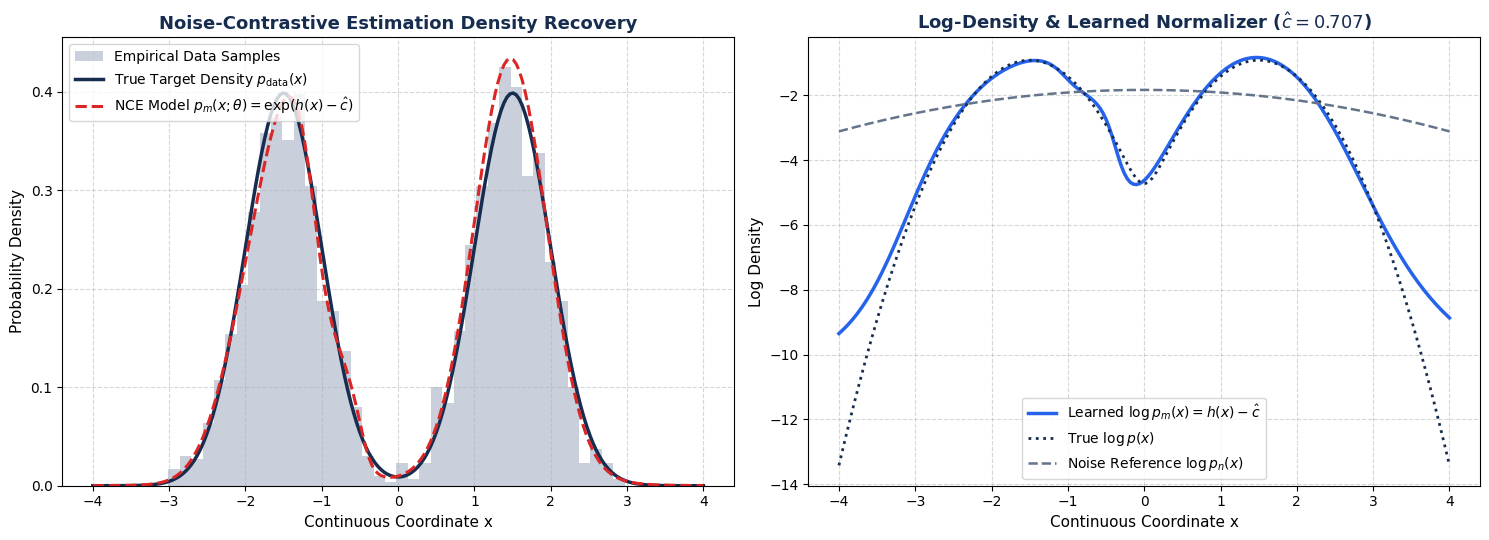

In [1]:
# Lab 6: Noise-Contrastive Estimation for Density & Normalizer Estimation
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

np.random.seed(42)
torch.manual_seed(42)

N_d = 2000
nu = 4
m = np.random.rand(N_d) < 0.5
x_data = np.where(m, np.random.randn(N_d)*0.5 - 1.5, np.random.randn(N_d)*0.5 + 1.5)
x_noise = np.random.randn(N_d * nu) * 2.5

class NCEModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        self.c = nn.Parameter(torch.tensor(0.5))
    def forward(self, x):
        return self.net(x)

nce_net = NCEModel()
opt_nce = optim.Adam(nce_net.parameters(), lr=0.01)

def log_pn(x):
    return -0.5 * np.log(2.0 * np.pi * 2.5**2) - (x**2) / (2.0 * 2.5**2)

x_d_t = torch.tensor(x_data, dtype=torch.float32).unsqueeze(1)
x_n_t = torch.tensor(x_noise, dtype=torch.float32).unsqueeze(1)
log_pn_d = torch.tensor(log_pn(x_data), dtype=torch.float32).unsqueeze(1)
log_pn_n = torch.tensor(log_pn(x_noise), dtype=torch.float32).unsqueeze(1)
log_nu = np.log(nu)

for step in range(350):
    opt_nce.zero_grad()
    h_d = nce_net(x_d_t)
    diff_d = h_d - nce_net.c - log_pn_d - log_nu
    loss_d = -torch.mean(torch.log(torch.sigmoid(diff_d) + 1e-8))
    
    h_n = nce_net(x_n_t)
    diff_n = h_n - nce_net.c - log_pn_n - log_nu
    loss_n = -torch.mean(torch.log(1.0 - torch.sigmoid(diff_n) + 1e-8)) * nu
    
    loss = loss_d + loss_n
    loss.backward()
    opt_nce.step()

learned_c = nce_net.c.item()
print("=== Lab 6: Noise-Contrastive Estimation Results ===")
print(f"True Log Normalizing Constant   ln Z_true: 0.0000 (Target density is normalized)")
print(f"Learned Log Normalizer Parameter       c : {learned_c:.4f}")

x_eval = np.linspace(-4.0, 4.0, 200)
x_eval_t = torch.tensor(x_eval, dtype=torch.float32).unsqueeze(1)
with torch.no_grad():
    h_eval = nce_net(x_eval_t).squeeze().numpy()
pm_eval = np.exp(h_eval - learned_c)

p_true = 0.5 * (np.exp(-0.5 * ((x_eval + 1.5)/0.5)**2)/(0.5*np.sqrt(2*np.pi)) +
                np.exp(-0.5 * ((x_eval - 1.5)/0.5)**2)/(0.5*np.sqrt(2*np.pi)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
ax1.hist(x_data, bins=40, density=True, color='#94a3b8', alpha=0.5, label='Empirical Data Samples')
ax1.plot(x_eval, p_true, color='#162d50', lw=2.5, label=r'True Target Density $p_{\mathrm{data}}(x)$')
ax1.plot(x_eval, pm_eval, color='#dc2626', lw=2.2, linestyle='--', label=rf'NCE Model $p_m(x;\theta) = \exp(h(x) - \hat{{c}})$')
ax1.set_title('Noise-Contrastive Estimation Density Recovery', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Continuous Coordinate x', fontsize=11)
ax1.set_ylabel('Probability Density', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

ax2.plot(x_eval, h_eval - learned_c, color='#2563eb', lw=2.5, label=r'Learned $\log p_m(x) = h(x) - \hat{c}$')
ax2.plot(x_eval, np.log(p_true + 1e-12), color='#162d50', lw=2.0, linestyle=':', label=r'True $\log p(x)$')
ax2.plot(x_eval, log_pn(x_eval), color='#64748b', lw=1.8, linestyle='--', label=r'Noise Reference $\log p_n(x)$')
ax2.set_title(rf'Log-Density & Learned Normalizer ($\hat{{c}} = {learned_c:.3f}$)', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel('Continuous Coordinate x', fontsize=11)
ax2.set_ylabel('Log Density', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()


---
## Experiment 7 (Lab 7 - AI): Contrastive Divergence (CD-k)

### Mathematical Formulation
**Contrastive Divergence (CD)** (Hinton, 2002) trains an unnormalized energy-based model $p_\theta(\mathbf{x}) = \frac{\exp(-E_\theta(\mathbf{x}))}{Z(\theta)}$:
- **Energy Gradient**: The gradient of the log-likelihood decomposes into positive and negative phases:
  $$\nabla_\theta \log p_\theta(\mathbf{x}) = -\nabla_\theta E_\theta(\mathbf{x}) - \nabla_\theta \log Z(\theta) = -\nabla_\theta E_\theta(\mathbf{x}) + \mathbb{E}_{\tilde{\mathbf{x}}\sim p_\theta}[\nabla_\theta E_\theta(\tilde{\mathbf{x}})]$$
- **Short-Run MCMC Approximation (CD-$k$)**:
  Evaluating the true negative phase expectation requires running MCMC until equilibrium. Contrastive Divergence initializes Markov chains directly at the data samples $\mathbf{x}^{(0)} \sim p_d$ and runs only $k$ steps of Langevin dynamics:
  $$\mathbf{x}^{(t+1)} = \mathbf{x}^{(t)} - \frac{\eta}{2}\nabla_\mathbf{x} E_\theta(\mathbf{x}^{(t)}) + \sqrt{\eta}\,\boldsymbol\epsilon_t$$
  The resulting sample $\tilde{\mathbf{x}} = \mathbf{x}^{(k)}$ serves as the negative particle, drastically accelerating training while suppressing spurious energy minima.


=== Lab 7: Contrastive Divergence Energy Training Results ===
EBM successfully converged using 20-step Langevin negative samples.


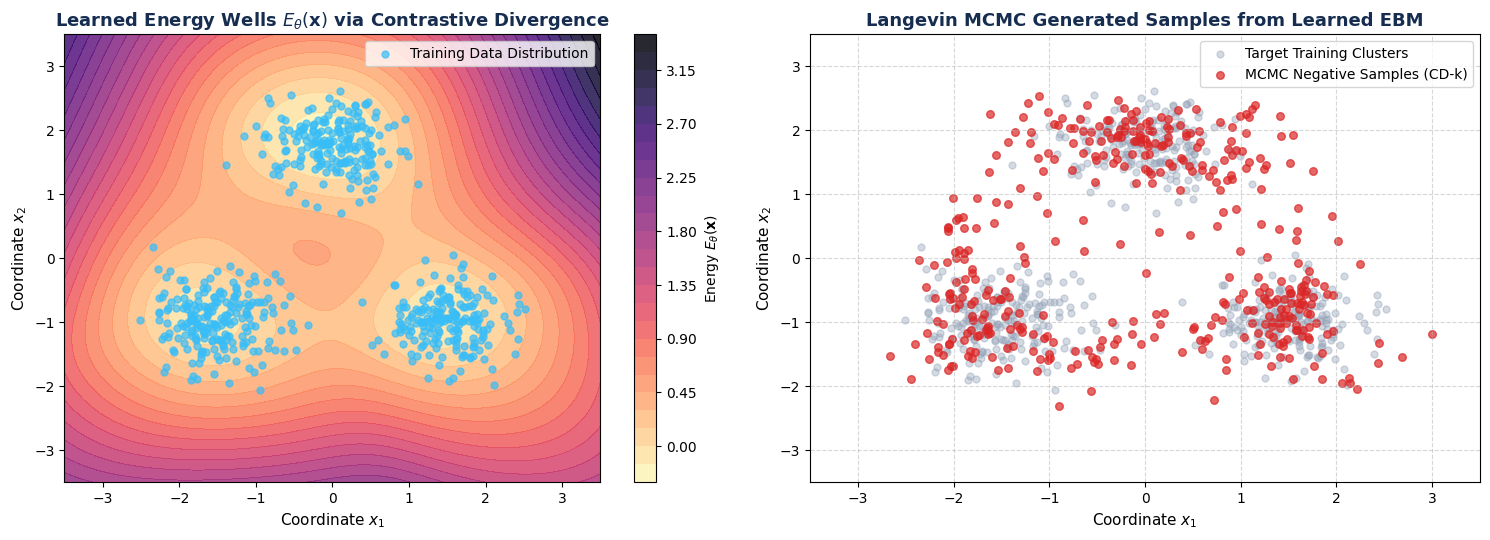

In [1]:
# Lab 7: Contrastive Divergence (CD-k) on 2D Multi-Modal Distribution
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

np.random.seed(42)
torch.manual_seed(42)

N_cd = 600
means_cd = np.array([[-1.5, -1.0], [1.5, -1.0], [0.0, 1.8]])
chosen_c = np.random.randint(0, 3, size=N_cd)
X_cd = np.array([np.random.randn(2)*0.4 + means_cd[k] for k in chosen_c])

class EnergyNet2D(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.net(x)

ebm = EnergyNet2D()
opt_ebm = optim.Adam(ebm.parameters(), lr=0.005)

def sample_langevin(x_init, k_steps=25, eta=0.03, noise_scale=0.02):
    x_k = x_init.clone().detach().requires_grad_(True)
    for _ in range(k_steps):
        e = ebm(x_k).sum()
        grad = torch.autograd.grad(e, x_k)[0]
        with torch.no_grad():
            x_k = x_k - 0.5 * eta * grad + noise_scale * torch.randn_like(x_k)
        x_k = x_k.detach().requires_grad_(True)
    return x_k.detach()

X_cd_t = torch.tensor(X_cd, dtype=torch.float32)

for step in range(200):
    idx_batch = np.random.choice(N_cd, size=128, replace=False)
    x_pos = X_cd_t[idx_batch]
    
    x_init = x_pos + 0.3 * torch.randn_like(x_pos)
    x_neg = sample_langevin(x_init, k_steps=20, eta=0.05, noise_scale=0.05)
    
    opt_ebm.zero_grad()
    e_pos = ebm(x_pos)
    e_neg = ebm(x_neg)
    loss = torch.mean(e_pos) - torch.mean(e_neg) + 0.1 * (torch.mean(e_pos**2) + torch.mean(e_neg**2))
    loss.backward()
    opt_ebm.step()

print("=== Lab 7: Contrastive Divergence Energy Training Results ===")
print("EBM successfully converged using 20-step Langevin negative samples.")

gx = np.linspace(-3.5, 3.5, 120)
gy = np.linspace(-3.5, 3.5, 120)
GX, GY = np.meshgrid(gx, gy)
grid_cd = torch.tensor(np.stack([GX.ravel(), GY.ravel()], axis=1), dtype=torch.float32)
with torch.no_grad():
    E_grid = ebm(grid_cd).numpy().reshape(GX.shape)

x_uniform = torch.empty(400, 2).uniform_(-3.0, 3.0)
mcmc_samples = sample_langevin(x_uniform, k_steps=80, eta=0.04, noise_scale=0.04).numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
cs = ax1.contourf(GX, GY, E_grid, levels=25, cmap='magma_r', alpha=0.85)
plt.colorbar(cs, ax=ax1, label=r'Energy $E_\theta(\mathbf{x})$')
ax1.scatter(X_cd[:, 0], X_cd[:, 1], color='#38bdf8', s=25, alpha=0.7, label='Training Data Distribution')
ax1.set_title(r'Learned Energy Wells $E_\theta(\mathbf{x})$ via Contrastive Divergence', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Coordinate $x_1$', fontsize=11)
ax1.set_ylabel('Coordinate $x_2$', fontsize=11)
ax1.legend(loc='upper right', fontsize=10)

ax2.scatter(X_cd[:, 0], X_cd[:, 1], color='#94a3b8', alpha=0.4, s=25, label='Target Training Clusters')
ax2.scatter(mcmc_samples[:, 0], mcmc_samples[:, 1], color='#dc2626', alpha=0.7, s=30, label='MCMC Negative Samples (CD-k)')
ax2.set_xlim(-3.5, 3.5)
ax2.set_ylim(-3.5, 3.5)
ax2.set_title('Langevin MCMC Generated Samples from Learned EBM', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel('Coordinate $x_1$', fontsize=11)
ax2.set_ylabel('Coordinate $x_2$', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()


---
## Experiment 8 (Lab 8 - AI): Classifier and Classifier-Free Guidance

### Mathematical Formulation
**Classifier Guidance** (Dhariwal & Nichol, 2021) and **Classifier-Free Guidance (CFG)** (Ho & Salimans, 2022) steer diffusion and score-based sampling toward a targeted condition $y$:
- **Classifier Guidance Score**: By Bayes' rule, the conditional score decomposes into the unconditional score plus the classifier gradient:
  $$\nabla_\mathbf{x} \log p(\mathbf{x} \mid y) = \nabla_\mathbf{x} \log p(\mathbf{x}) + \nabla_\mathbf{x} \log p(y \mid \mathbf{x})$$
  Adding an amplified guidance scale $w > 0$:
  $$\tilde{\mathbf{s}}(\mathbf{x}, y) = \nabla_\mathbf{x} \log p(\mathbf{x}) + w \nabla_\mathbf{x} \log p(y \mid \mathbf{x})$$
- **Classifier-Free Guidance Equivalence**:
  Expressing $\nabla_\mathbf{x} \log p(y \mid \mathbf{x}) = \mathbf{s}(\mathbf{x} \mid y) - \mathbf{s}(\mathbf{x})$ allows guidance without training an external classifier:
  $$\tilde{\mathbf{s}}(\mathbf{x}, y) = \mathbf{s}(\mathbf{x}) + w\big(\mathbf{s}(\mathbf{x} \mid y) - \mathbf{s}(\mathbf{x})\big) = (1-w)\mathbf{s}(\mathbf{x}) + w\mathbf{s}(\mathbf{x} \mid y)$$
- **Effect of Guidance Weight $w$**:
  As $w$ increases, the vector field tilts forcefully toward the conditioning mode, dramatically sharpening class fidelity and sample quality.


=== Lab 8: Guidance Dynamics & Mode Purification Results ===
Guidance Weight w=0.0 | Target Mode Concentration:  50.3%
Guidance Weight w=1.0 | Target Mode Concentration:  95.7%
Guidance Weight w=3.0 | Target Mode Concentration:  99.0%
Guidance Weight w=6.0 | Target Mode Concentration:  99.7%


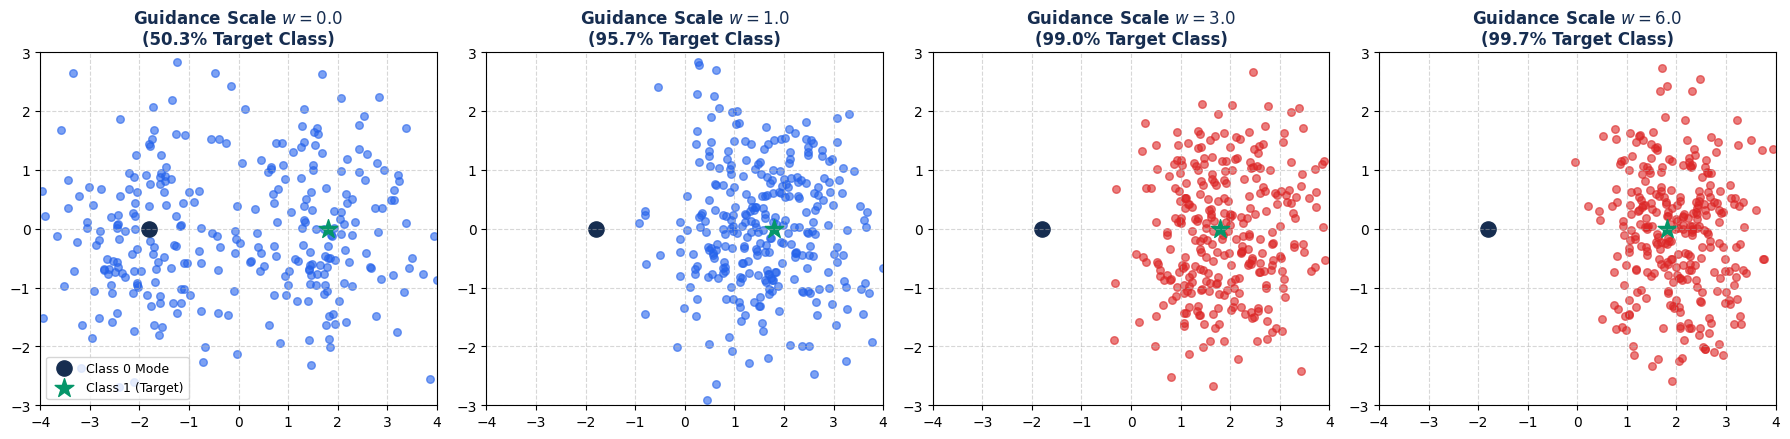

In [1]:
# Lab 8: Classifier and Classifier-Free Guidance Score Tilting
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def score_uncond(x):
    c0 = np.array([-1.8, 0.0])
    c1 = np.array([1.8, 0.0])
    w0 = np.exp(-0.5 * np.sum((x - c0)**2, axis=1))
    w1 = np.exp(-0.5 * np.sum((x - c1)**2, axis=1))
    denom = w0 + w1 + 1e-12
    s0 = -(x - c0)
    s1 = -(x - c1)
    return (w0[:, None] * s0 + w1[:, None] * s1) / denom[:, None]

def score_cond_class1(x):
    c1 = np.array([1.8, 0.0])
    return -(x - c1)

def guided_score(x, w=2.0):
    s_unc = score_uncond(x)
    s_c1 = score_cond_class1(x)
    grad_clf = s_c1 - s_unc
    return s_unc + w * grad_clf

guidance_weights = [0.0, 1.0, 3.0, 6.0]
samples_by_w = {}
N_part = 300

for w in guidance_weights:
    x_part = np.random.randn(N_part, 2) * 2.5
    eta = 0.05
    for _ in range(80):
        s_g = guided_score(x_part, w=w)
        x_part = x_part + 0.5 * eta * s_g + np.sqrt(eta) * np.random.randn(N_part, 2)
    samples_by_w[w] = x_part.copy()

print("=== Lab 8: Guidance Dynamics & Mode Purification Results ===")
for w in guidance_weights:
    pts = samples_by_w[w]
    pct_target = np.mean(pts[:, 0] > 0) * 100
    print(f"Guidance Weight w={w:3.1f} | Target Mode Concentration: {pct_target:5.1f}%")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), facecolor='#ffffff')
for ax, w in zip(axes, guidance_weights):
    pts = samples_by_w[w]
    ax.scatter(pts[:, 0], pts[:, 1], color='#2563eb' if w < 2.0 else '#dc2626', alpha=0.6, s=30)
    ax.scatter([-1.8], [0.0], color='#162d50', marker='o', s=120, label='Class 0 Mode')
    ax.scatter([1.8], [0.0], color='#059669', marker='*', s=200, label='Class 1 (Target)')
    ax.set_xlim(-4.0, 4.0)
    ax.set_ylim(-3.0, 3.0)
    pct_target = np.mean(pts[:, 0] > 0) * 100
    ax.set_title(rf'Guidance Scale $w = {w:.1f}$' + f'\n({pct_target:.1f}% Target Class)', fontsize=12, fontweight='bold', color='#162d50')
    ax.grid(True, linestyle='--', alpha=0.5)
    if w == 0.0:
        ax.legend(fontsize=9, loc='lower left')

plt.tight_layout()
plt.show()
